In [3]:
from sklearn.feature_selection import mutual_info_classif
from scipy.stats import pointbiserialr
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, cross_validate

from sklearn.metrics import (
    roc_curve,
    roc_auc_score,
    precision_recall_curve,
    average_precision_score
)

df = pd.read_csv(r"D:\1_Python Programmes\Projects\HDD\data\heart_disease_cleaned.csv")

X = df.drop(columns = ["id","dataset","num"])
y = df["num"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)
categorical_features = X_train.select_dtypes(
    include=["object", "category"]
).columns

for col in categorical_features:
    X_train[col] = X_train[col].map(
        lambda value: str(value) if pd.notna(value) else np.nan
    )

In [4]:
# Create a separate copy
X_mi = X_train.copy()

# Identify feature types
categorical_features = X_mi.select_dtypes(
    include=["object", "category"]
).columns.tolist()

numerical_features = X_mi.select_dtypes(
    include=np.number
).columns.tolist()

# Treat CA as a discrete count feature
discrete_features = categorical_features + ["ca"]

# Encode categorical variables as integer category codes
for col in categorical_features:

    X_mi[col] = (
        X_mi[col]
        .fillna("__MISSING__")
        .astype(str)
    )

    X_mi[col] = pd.factorize(X_mi[col])[0]

# Handle missing numerical values using median imputation
for col in numerical_features:

    X_mi[col] = X_mi[col].fillna(
        X_mi[col].median()
    )

# Create discrete feature mask
discrete_mask = [
    col in discrete_features
    for col in X_mi.columns
]

print("Prepared dataset shape:", X_mi.shape)
print("Discrete features:", discrete_features)

Prepared dataset shape: (736, 13)
Discrete features: ['sex', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'thal', 'ca']


In [6]:
mi_scores = mutual_info_classif(
    X_mi,
    y_train,
    discrete_features=discrete_mask,
    n_neighbors=3,
    random_state=42
)

# Create results DataFrame
mi_results = pd.DataFrame({
    "Feature": X_mi.columns,
    "MI Score": mi_scores
})

# Sort by MI score
mi_results = mi_results.sort_values(
    by="MI Score",
    ascending=False
)

print(mi_results.round(4))

     Feature  MI Score
2         cp    0.1420
8      exang    0.1080
7     thalch    0.0913
9    oldpeak    0.0778
10     slope    0.0768
0        age    0.0618
12      thal    0.0613
3   trestbps    0.0518
1        sex    0.0473
4       chol    0.0469
5        fbs    0.0307
11        ca    0.0182
6    restecg    0.0077


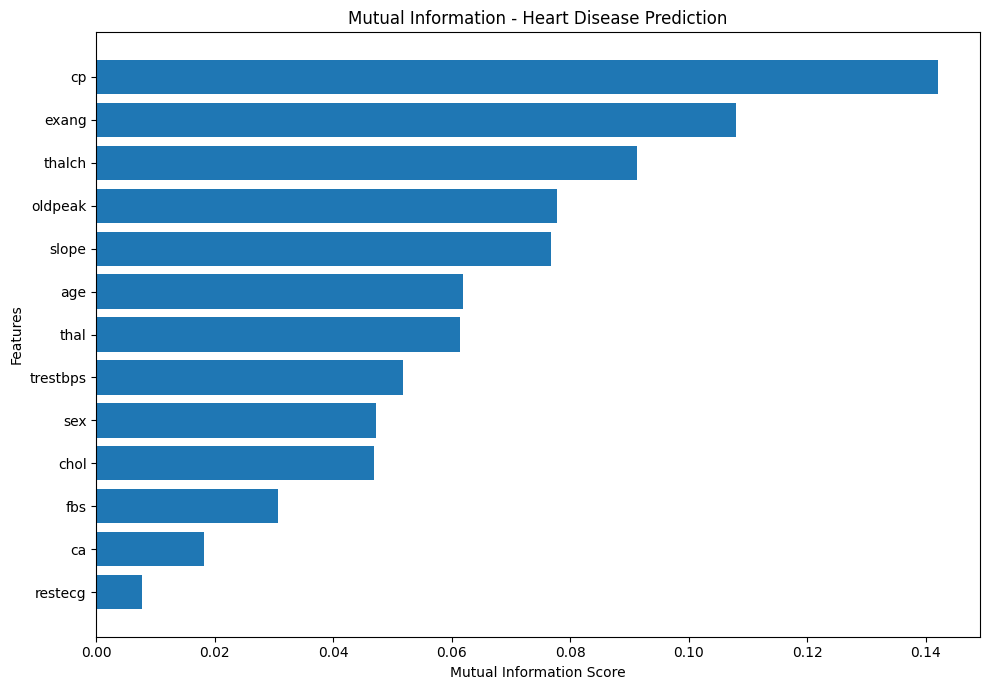

In [10]:
plt.figure(figsize=(10, 7))

plt.barh(
    mi_results["Feature"],
    mi_results["MI Score"]
)

plt.xlabel("Mutual Information Score")
plt.ylabel("Features")
plt.title("Mutual Information - Heart Disease Prediction")

plt.gca().invert_yaxis()

plt.tight_layout()

# plt.savefig(
#     "D:/1_Python Programmes/Projects/HDD/reports/mutual_information.png",
#     dpi=300
# )

plt.show()